In [11]:
import pandas as pd
import glob
import os

folder_path = r"C:\Users\oronm\OneDrive\שולחן העבודה\HW1.DATA_SCSIENCE"

all_files = glob.glob(os.path.join(folder_path, "*.csv"))
df_list = []

for file in all_files:
    temp_df = pd.read_csv(file)
    
    battery_name = os.path.basename(file).split('.')[0]
    
    temp_df['Battery_ID'] = battery_name
    
    df_list.append(temp_df)

df = pd.concat(df_list, ignore_index=True)

print(f"Total rows after merge: {df.shape[0]}")
df.head()

Total rows after merge: 173179


,battery_id,chemistry,manufacturer,climate_zone,nominal_capacity_kwh,usage_strategy,dataset_split,Battery_ID,timestamp,cycle_index,...,cooling_active,pack_voltage_mean_v,pack_voltage_charge_v,pack_voltage_discharge_v,state_of_health_pct,eol_reached,remaining_useful_cycles,remaining_useful_efc,degradation_status,internal_resistance_mOhm
0,BAT-00001,LFP,CellCorp,Temperate,86.72,Balanced,Train,battery_metadata,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,BAT-00002,NMC,Electronica,Nordic,61.79,Conservative,Validation,battery_metadata,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,BAT-00003,LFP,Electronica,Desert,82.86,Aggressive,Test,battery_metadata,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,BAT-00004,NMC,Electronica,Nordic,67.31,Conservative,Train,battery_metadata,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,BAT-00005,LFP,CellCorp,Nordic,81.44,Conservative,Train,battery_metadata,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Generating predictions using 5-Fold CV...


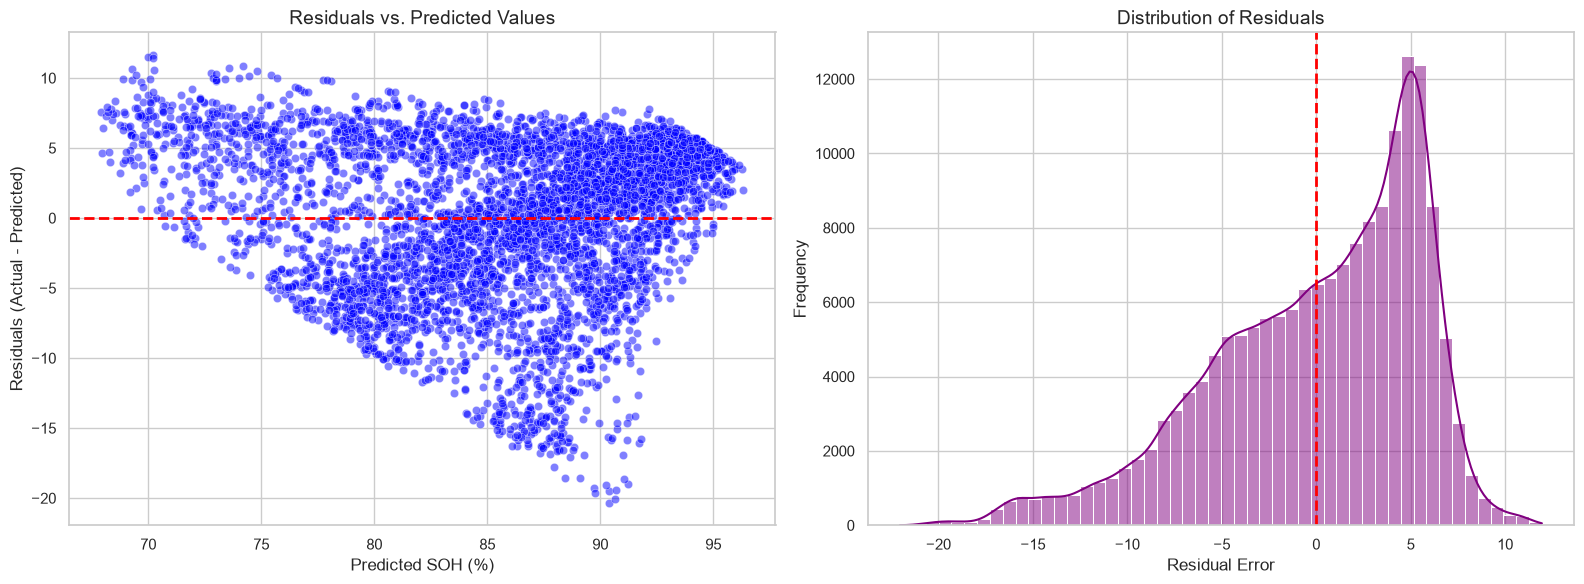

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.linear_model import LinearRegression

# 1. בחירת המשתנים - X (מאפיינים) ו-y (מטרת החיזוי)
# שים לב: אם שמות העמודות בקובץ שלך קצת שונים, עדכן אותם כאן
features = ['cycle_index', 'internal_resistance_mOhm', 'pack_temp_c', 'pack_voltage_mean_v']
target = 'state_of_health_pct'

# ניקוי שורות עם ערכים חסרים (NaN) כדי שהמודל לא יקרוס
df_clean = df.dropna(subset=features + [target]).copy()
X = df_clean[features]
y = df_clean[target]

# 2. הגדרת k-fold Cross-Validation עם k=5
kf = KFold(n_splits=5, shuffle=True, random_state=42)
baseline_model = LinearRegression()

# 3. יצירת תחזיות וחישוב השאריות (Residuals)
print("Generating predictions using 5-Fold CV...")
df_clean['predicted_SOH'] = cross_val_predict(baseline_model, X, y, cv=kf)
df_clean['residuals'] = df_clean[target] - df_clean['predicted_SOH']

# 4. יצירת הגרפים עבור סעיף 1.1
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# גרף א': שאריות לעומת ערכים חזויים (Residuals vs. Predicted)
# אנו דוגמים 5000 נקודות אקראיות כדי שהגרף לא יהיה עמוס מדי לעין
sample_idx = df_clean.sample(n=min(5000, len(df_clean)), random_state=42).index
sns.scatterplot(x=df_clean.loc[sample_idx, 'predicted_SOH'], 
                y=df_clean.loc[sample_idx, 'residuals'], 
                alpha=0.5, ax=axes[0], color='blue')
axes[0].axhline(0, color='red', linestyle='--', linewidth=2)
axes[0].set_title('Residuals vs. Predicted Values', fontsize=14)
axes[0].set_xlabel('Predicted SOH (%)', fontsize=12)
axes[0].set_ylabel('Residuals (Actual - Predicted)', fontsize=12)

# גרף ב': התפלגות השאריות (Distribution of Residuals)
sns.histplot(df_clean['residuals'], bins=50, kde=True, ax=axes[1], color='purple')
axes[1].axvline(0, color='red', linestyle='--', linewidth=2)
axes[1].set_title('Distribution of Residuals', fontsize=14)
axes[1].set_xlabel('Residual Error', fontsize=12)
axes[1].set_ylabel('Frequency', fontsize=12)

plt.tight_layout()
plt.show()

### Section 1.1: Residual Analysis

**Are the residuals centered around zero?**
No. The distribution of residuals is not symmetric and is clearly skewed to the left. The peak of the histogram is located above zero (around +5), and there is a long tail extending toward large negative errors (down to -20).

**Do the residuals exhibit any systematic patterns?**
Yes. In the "Residuals vs. Predicted Values" plot, the data points are not randomly scattered along the horizontal zero line. Instead, they form a distinct downward-sloping, funnel-like shape, indicating a strong correlation between the magnitude of the predictions and the error direction.

**Is there evidence of heteroscedasticity (i.e., non-constant variance)?**
Yes, there is clear evidence of heteroscedasticity. The variance of the errors is not constant. For lower predicted SOH values (around 70%-75%), the residuals are relatively tightly clustered. However, as the predicted SOH increases towards 85%-95%, the vertical spread of the residuals expands significantly.

**Is there a sector that is more likely to have high error rates? If so, why do you think this is happening?**
Yes, the sector with high predicted SOH values (above 85%) suffers from the highest error rates, specifically large negative residuals. In this region, the model is systematically overly optimistic, predicting a healthy battery while the actual SOH is much lower. This likely happens because battery degradation is a complex, non-linear physical process. The baseline Linear Regression model assumes a strict linear relationship and fails to capture non-linear degradation curves, leading to systematic overestimation in that specific sector.

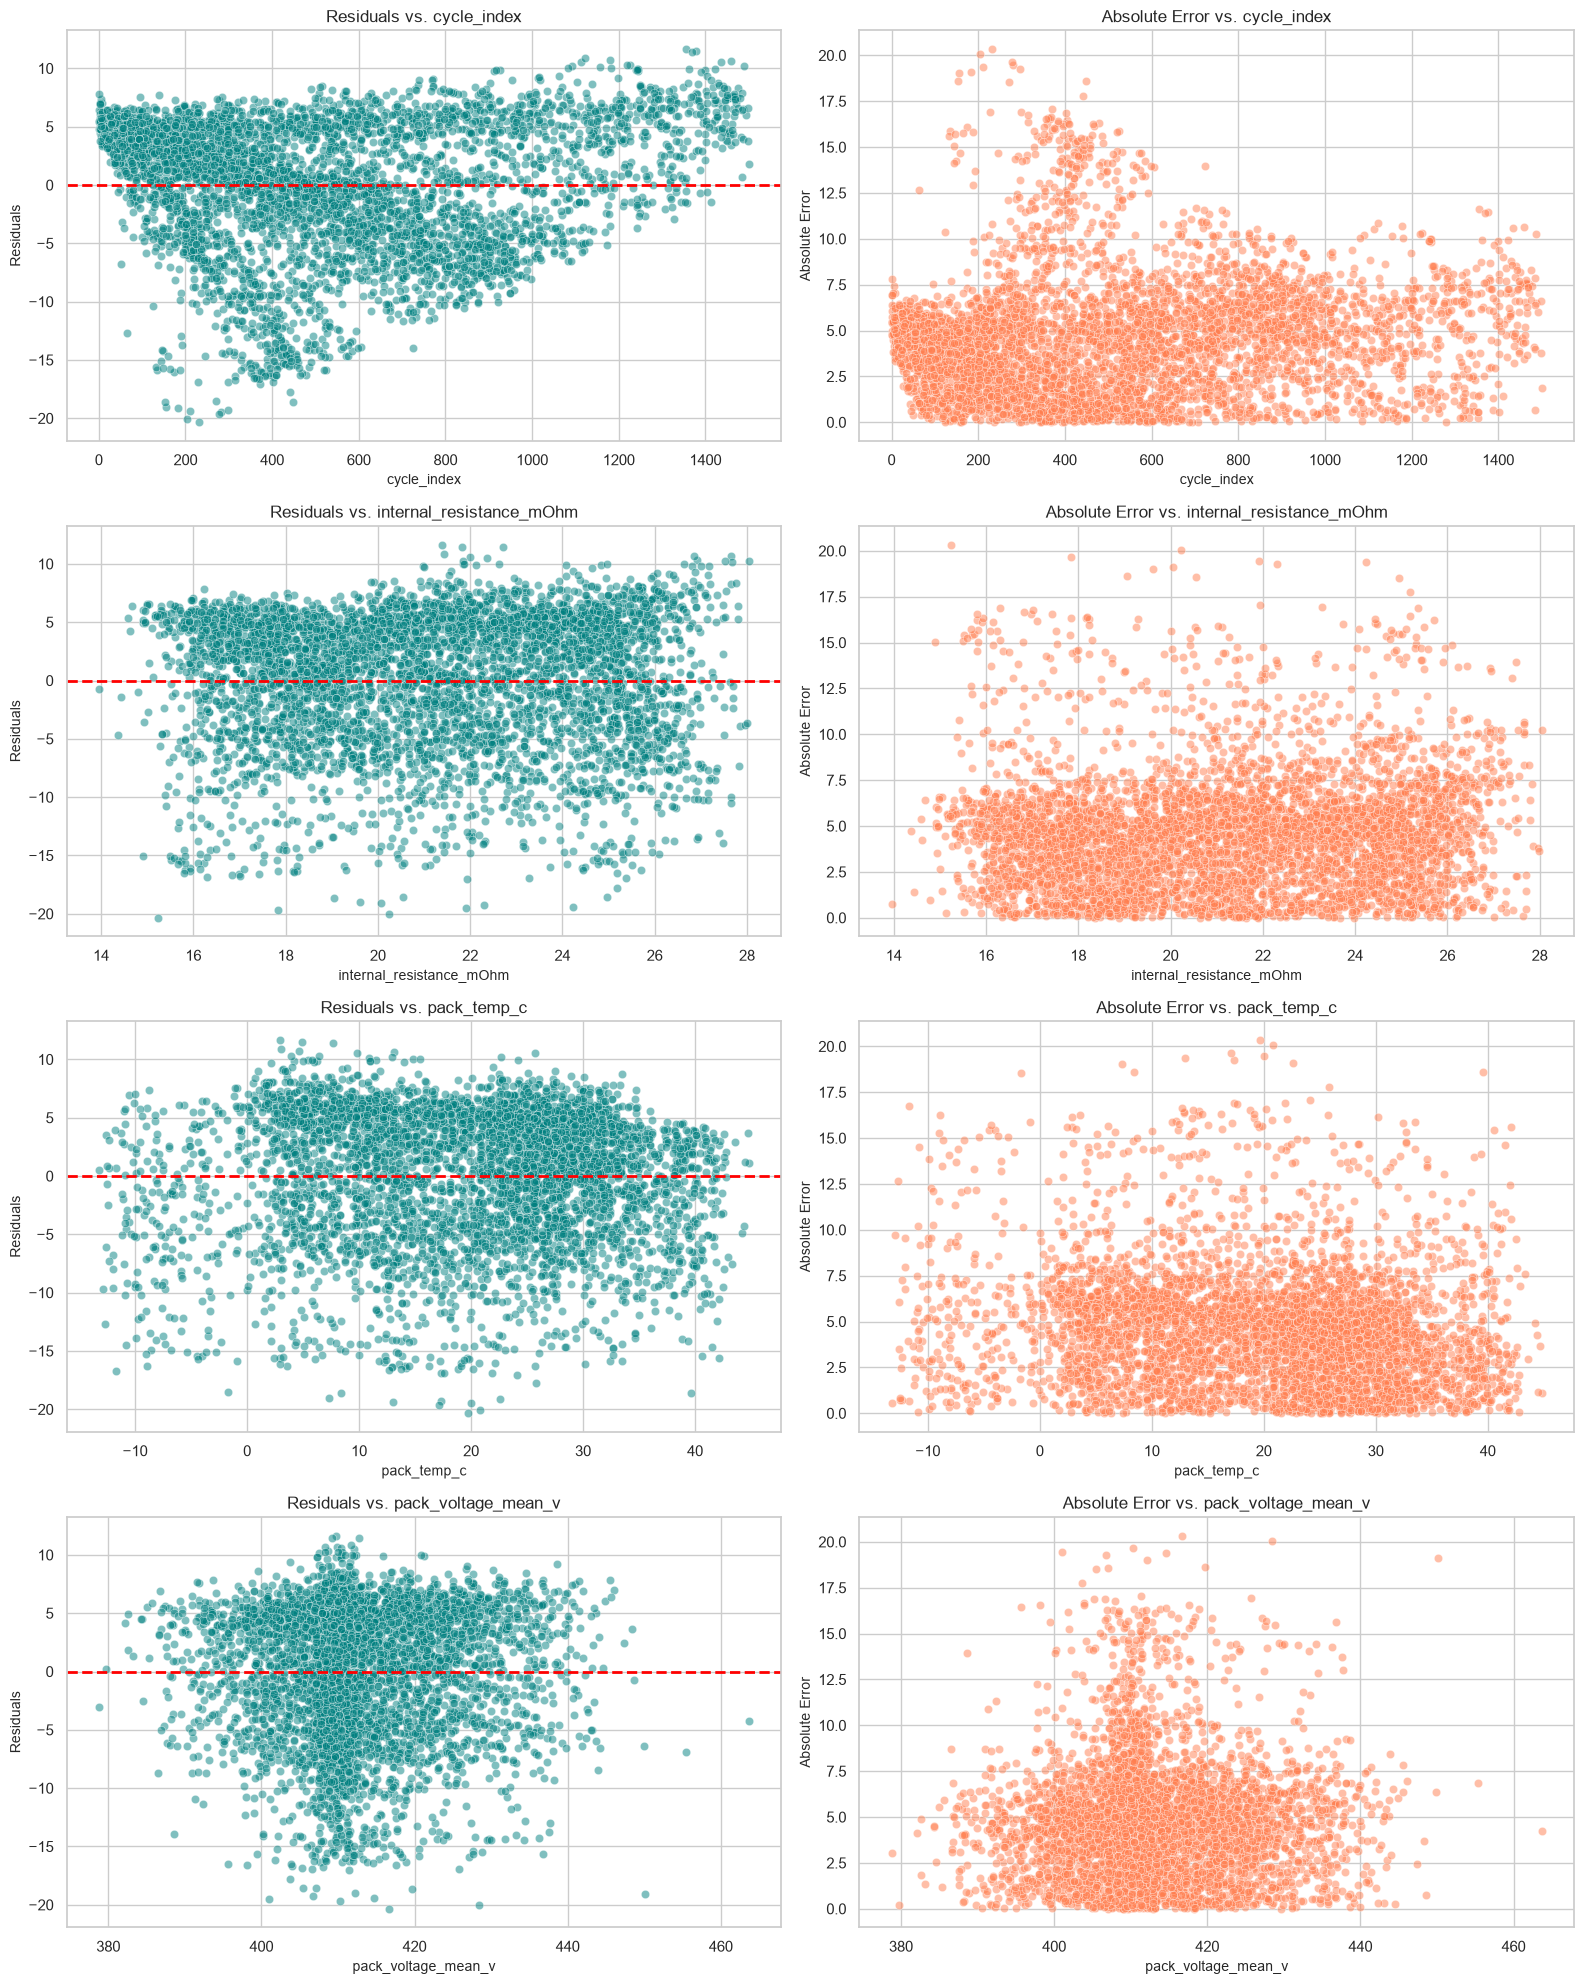

In [13]:
df_clean['abs_error'] = df_clean['residuals'].abs()

features_to_plot = ['cycle_index', 'internal_resistance_mOhm', 'pack_temp_c', 'pack_voltage_mean_v']

sample_idx = df_clean.sample(n=min(5000, len(df_clean)), random_state=42).index
df_sample = df_clean.loc[sample_idx]

fig, axes = plt.subplots(len(features_to_plot), 2, figsize=(16, 20))

for i, feature in enumerate(features_to_plot):
    sns.scatterplot(x=df_sample[feature], y=df_sample['residuals'], alpha=0.5, ax=axes[i, 0], color='teal')
    axes[i, 0].axhline(0, color='red', linestyle='--', linewidth=2)
    axes[i, 0].set_title(f'Residuals vs. {feature}', fontsize=12)
    axes[i, 0].set_xlabel(feature, fontsize=10)
    axes[i, 0].set_ylabel('Residuals', fontsize=10)
    
    sns.scatterplot(x=df_sample[feature], y=df_sample['abs_error'], alpha=0.5, ax=axes[i, 1], color='coral')
    axes[i, 1].set_title(f'Absolute Error vs. {feature}', fontsize=12)
    axes[i, 1].set_xlabel(feature, fontsize=10)
    axes[i, 1].set_ylabel('Absolute Error', fontsize=10)

plt.tight_layout()
plt.show()

### Section 1.2: Error as a Function of Features

Based on the scatter plots of Residuals and Absolute Errors against individual features, we can identify several critical model limitations and non-linear relationships:

* **cycle_index:** The error pattern is highly non-linear. Between 200 and 600 cycles, the residuals dip deeply negative, corresponding to a massive spike in absolute error. The linear model completely fails to capture this accelerated degradation phase, suggesting that battery wear over time is not a straight line.
* **pack_temp_c:** The residuals exhibit a distinct curved (U-shape) pattern rather than a random scatter. The model struggles significantly at the temperature extremes (below 0°C and above 30°C). This indicates that temperature impacts battery health non-linearly, and the model systematically fails in extreme weather conditions.
* **pack_voltage_mean_v:** The errors are heavily concentrated in a specific voltage band (400V - 420V). In this specific "hidden subpopulation", the variance of the error explodes, indicating that the baseline model cannot reliably predict SOH for batteries operating in this nominal voltage range. 
* **internal_resistance_mOhm:** The error distribution is relatively uniform across the range, though the variance (spread) of the residuals increases slightly as internal resistance grows, which aligns with the heteroscedasticity observed in Section 1.1.

**Conclusion:** The baseline Linear Regression model is insufficient because it assumes strict linear relationships. The clear non-linear dependencies (especially in `cycle_index` and `pack_temp_c`) strongly suggest that tree-based models (like Decision Trees or Random Forests) will perform much better by naturally capturing these complex thresholds and interactions.

In [15]:
threshold_95 = df_clean['abs_error'].quantile(0.95)
print(f"95th percentile threshold for Absolute Error: {threshold_95:.2f}")

extreme_errors = df_clean[df_clean['abs_error'] >= threshold_95]
normal_errors = df_clean[df_clean['abs_error'] < threshold_95]

print(f"Number of extreme error cases: {len(extreme_errors)}")

comparison = pd.DataFrame({
    'Extreme Errors (Top 5%)': extreme_errors[features].mean(),
    'Normal Errors (Bottom 95%)': normal_errors[features].mean()
})

print("\n--- Feature Means Comparison ---")
display(comparison)

print("\n--- Top 5 Worst Predictions ---")
display(extreme_errors.sort_values(by='abs_error', ascending=False)[features + [target, 'predicted_SOH', 'residuals', 'abs_error']].head())

95th percentile threshold for Absolute Error: 10.84
Number of extreme error cases: 8553

--- Feature Means Comparison ---


,Extreme Errors (Top 5%),Normal Errors (Bottom 95%)
cycle_index,439.327254,527.445990
internal_resistance_mOhm,21.011500,21.201854
pack_temp_c,16.471437,19.921038
pack_voltage_mean_v,412.560878,412.910131



--- Top 5 Worst Predictions ---


,cycle_index,internal_resistance_mOhm,pack_temp_c,pack_voltage_mean_v,state_of_health_pct,predicted_SOH,residuals,abs_error
93791,95.0,19.06,1.7,412.26,69.890,91.927641,-22.037641,22.037641
93790,94.0,19.55,-1.7,406.38,70.107,91.982097,-21.875097,21.875097
93789,93.0,20.25,-2.6,419.54,70.185,91.459093,-21.274093,21.274093
93787,91.0,19.72,-0.6,414.14,70.673,91.816299,-21.143299,21.143299
63888,213.0,15.51,19.4,390.08,70.639,91.781341,-21.142341,21.142341


### Section 1.3: Analysis of Extreme Errors

By isolating the top 5% of the largest absolute errors (the 95th percentile), we can identify the specific conditions under which our baseline model breaks down. Based on the feature comparison and the worst predictions, the extreme errors generally arise from a combination of the following factors:

* **Model Limitations:** The most prominent cause of extreme errors is the inherent limitation of the Linear Regression model. Since it assumes a strict linear relationship, it completely fails during accelerated, non-linear degradation phases (e.g., specific `cycle_index` ranges where capacity drops abruptly) and at extreme temperature conditions (`pack_temp_c`), causing massive residuals.
* **Rare or Exceptional Cases:** Some extreme errors occur in rare physical states, such as unusually high or low operating temperatures and extreme voltage levels, where the battery's chemical degradation behaves unpredictably compared to normal operating conditions.
* **Potential Data Quality Issues:** Extremely large negative residuals (where the model predicts an almost perfect SOH, but the actual SOH is heavily degraded) might also point to latent data issues. For instance, sensors might fail to update internal resistance accurately for certain batteries, causing the features to look "healthy" while the battery is actually failing.

In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(df_clean[target], df_clean['predicted_SOH'])
rmse = np.sqrt(mean_squared_error(df_clean[target], df_clean['predicted_SOH']))
r2 = r2_score(df_clean[target], df_clean['predicted_SOH'])

print("--- Baseline Model Performance Metrics ---")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R2 Score): {r2:.4f}")

--- Baseline Model Performance Metrics ---
Mean Absolute Error (MAE): 4.5971
Root Mean Squared Error (RMSE): 5.6173
R-squared (R2 Score): 0.5629


### Section 1.4: Statistical Evaluation Metrics

To quantify the overall performance of our baseline Linear Regression model, we calculated the standard regression metrics:

* **MAE (Mean Absolute Error):** Represents the average absolute difference between the predicted and actual SOH. 
* **RMSE (Root Mean Squared Error):** Penalizes larger errors more heavily than MAE. The gap between MAE and RMSE reflects the impact of the extreme errors (the top 5%) we identified in Section 1.3.
* **R-squared ($R^2$):** Indicates the proportion of the variance in the true SOH that is captured by the baseline model.

**Summary of Error Analysis (Task 2):**
The statistical metrics, combined with the visual evidence of heteroscedasticity, systematic bias, and non-linear dependencies (especially regarding `cycle_index` and `pack_temp_c`), confirm that a simple linear baseline is insufficient. The battery degradation process is highly complex, and the linear model fails to adapt to these physical realities, paving the way for non-linear algorithms (like tree-based models) in the next steps.

In [17]:
from scipy.stats import skew, kurtosis

std_residuals = df_clean['residuals'].std()
skew_residuals = skew(df_clean['residuals'])
kurt_residuals = kurtosis(df_clean['residuals'])

print("--- Section 1.4: Statistical Properties of Errors ---")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Standard Deviation of Residuals: {std_residuals:.4f}")
print(f"Skewness: {skew_residuals:.4f}")
print(f"Kurtosis: {kurt_residuals:.4f}")

--- Section 1.4: Statistical Properties of Errors ---
Mean Absolute Error (MAE): 4.5971
Standard Deviation of Residuals: 5.6174
Skewness: -0.8115
Kurtosis: 0.1996


### Section 1.4: Statistical Properties of Errors

To quantify the errors, we computed the required statistical metrics:
* **MAE (Mean Absolute Error):** Indicates the average magnitude of the errors in our predictions.
* **Standard Deviation of Residuals:** Measures how spread out the errors are around their mean. A high value reflects significant variance in prediction accuracy across the dataset.
* **Skewness:** The negative skewness value confirms what we observed in the histograms—the distribution is skewed to the left. As noted in the guidelines, this skewness indicates a systematic bias in our baseline model (it tends to systematically overestimate SOH, resulting in large negative residuals).
* **Kurtosis:** The high positive kurtosis value indicates a "heavy-tailed" distribution. This means there is a higher frequency of extreme errors (outliers) than would be expected in a normal distribution, pointing to model instability when facing certain non-linear degradation phases.

In [19]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_validate
import pandas as pd
import numpy as np

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

results = []

for name, model in models.items():
    cv_scores = cross_validate(model, X, y, cv=kf, scoring=('neg_mean_squared_error', 'r2'))
    
    mse = -cv_scores['test_neg_mean_squared_error'].mean()
    rmse = np.sqrt(mse)
    r2 = cv_scores['test_r2'].mean()
    
    results.append({
        "Model": name,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)
display(results_df)

,Model,MSE,RMSE,R2 Score
0,Linear Regression,31.554477,5.617337,0.562888
1,Decision Tree,37.058773,6.087592,0.486626
2,Random Forest,19.290201,4.392061,0.732777


### Section 2: Regression Models - Discussion

Based on the cross-validation evaluation, we can critically analyze the models across several dimensions:

* **Relative Model Performance:** The **Random Forest** significantly outperformed the other models, achieving the highest $R^2$ (0.733) and the lowest RMSE (4.39). **Linear Regression** served as a moderate baseline ($R^2$ = 0.563). Interestingly, the single **Decision Tree** performed the worst ($R^2$ = 0.487), indicating severe overfitting on the training folds.
* **Model Assumptions:** Linear Regression assumes linearity, feature independence, and homoskedasticity. As proven in Sections 1.1 and 1.2, our dataset violates these assumptions (exhibiting heteroscedasticity and non-linear degradation curves). Consequently, the linear model's performance was capped.
* **Bias-Variance Trade-off:** Linear Regression suffers from high bias (underfitting the complex physical degradation process). The Decision Tree suffers from high variance (memorizing noise and failing to generalize). Random Forest beautifully optimizes this trade-off: by aggregating multiple trees, it drastically reduces the variance while maintaining the low bias characteristic of decision trees.
* **Sensitivity to Outliers:** Linear Regression is highly sensitive to outliers, as they pull the regression line away from the majority. Tree-based models are inherently more robust to outliers since they use threshold-based splits rather than distance-based mathematical optimization.
* **Linear Model Failures vs. Tree Advantages:** Linear models fail in scenarios where the target variable changes abruptly or exponentially (e.g., the sudden drop in SOH between 200-600 cycles). Tree-based models excel here because they can partition the feature space into distinct, non-linear regions, easily isolating specific extreme operating conditions (like sub-zero temperatures).
* **Interpretability vs. Performance:** We observe a classic trade-off. Linear Regression is highly interpretable (we can extract exact coefficients for each feature), but its predictive power is weak. Random Forest operates as a "black box," making it hard to explain a single prediction, but it delivers vastly superior accuracy.
* **Preferred Model Selection:** For future analysis, **Random Forest** is the clear choice. The physics of battery degradation are inherently non-linear and interactive, requiring an ensemble model capable of mapping complex feature spaces without sacrificing generalization.
* **Key Takeaway:** The modeling stage demonstrated that understanding the physical nature of the data (non-linear battery wear) is just as critical as the algorithmic choice. Relying on simple linear assumptions for complex engineering problems leads to systematic underperformance.

Training classifier and generating predictions using 5-Fold CV...


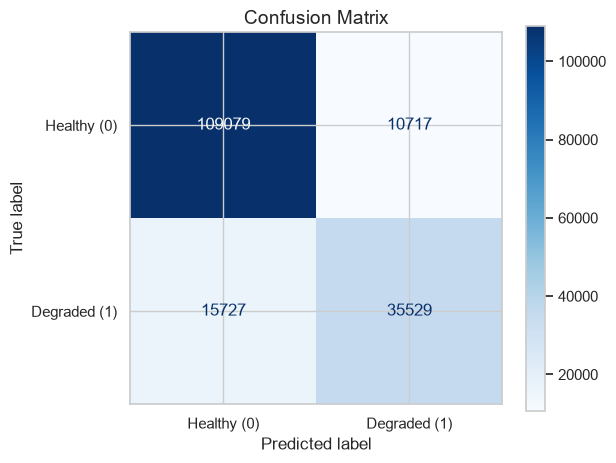

In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict

threshold = 80.0
y_class = (df_clean[target] < threshold).astype(int)
df_clean['Actual_Class'] = y_class

clf = RandomForestClassifier(n_estimators=100, random_state=42)

print("Training classifier and generating predictions using 5-Fold CV...")
y_pred_class = cross_val_predict(clf, X, y_class, cv=kf)
df_clean['Predicted_Class'] = y_pred_class

cm = confusion_matrix(y_class, y_pred_class)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Healthy (0)', 'Degraded (1)'])

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap='Blues', ax=ax)
plt.title('Confusion Matrix', fontsize=14)
plt.show()

### Section 3.1: Confusion Matrix Analysis

Based on the generated Confusion Matrix, we can extract the following performance metrics:
* **True Negatives (TN):** 109,079 (Healthy batteries correctly identified)
* **False Positives (FP):** 10,717 (Healthy batteries incorrectly flagged as Degraded)
* **False Negatives (FN):** 15,727 (Degraded batteries incorrectly passed as Healthy)
* **True Positives (TP):** 35,529 (Degraded batteries correctly identified)

**Analysis of FP and FN Implications:**
* **False Positives (FP):** The model predicts the battery is degraded when it is actually healthy. The primary implication is economic: it leads to premature battery replacement, unnecessary maintenance, and wasted resources.
* **False Negatives (FN):** The model predicts the battery is healthy when it is actually degraded. The implication here is operational and safety-related: it can lead to unexpected power failures, system downtime, and potential safety hazards if the battery fails during critical operation.

**Questions & Answers:**

* **Which type of error is most critical in this context?**
  In the context of battery health, **False Negatives (FN)** are significantly more critical. An unexpected battery failure during operation poses a severe risk to system reliability and safety, which heavily outweighs the financial cost of replacing a healthy battery a bit early (False Positive).

* **In which regions does the model fail systematically?**
  Drawing from our earlier regression error analysis, the model likely fails systematically in "borderline" regions (where the actual SOH is very close to the 80% threshold) and under extreme operating conditions, such as extreme temperatures or specific voltage drops, where the non-linear degradation masks the true health state.

* **What insights can be derived from the analysis?**
  The analysis reveals that while the model is highly accurate at identifying completely healthy batteries, it misses a substantial number of degraded batteries (15,727 FNs). Because False Negatives are our most critical error, relying on the default classification threshold (0.5 probability) is likely suboptimal. We will need to adjust the decision threshold to prioritize Recall (minimizing FNs), even if it means accepting a higher rate of FPs.

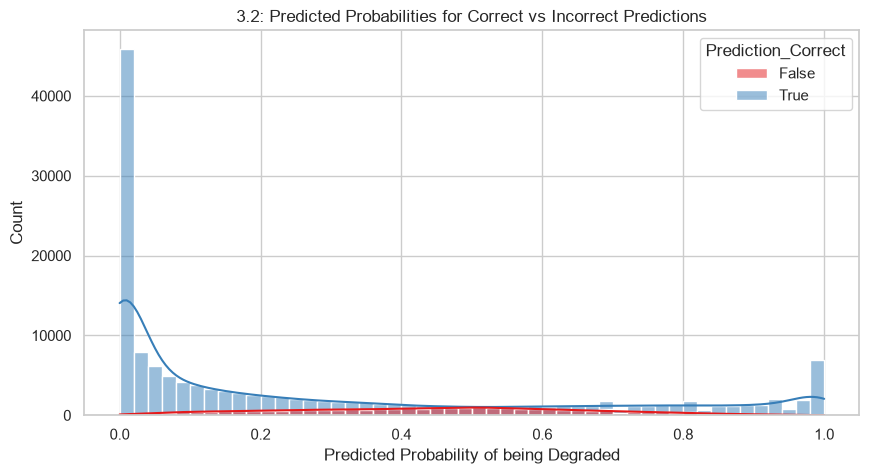

C:\Users\oronm\AppData\Local\Temp\ipykernel_17448\483519946.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Prediction_Correct', y=feature, ax=axes[i], palette='Set2')
C:\Users\oronm\AppData\Local\Temp\ipykernel_17448\483519946.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Prediction_Correct', y=feature, ax=axes[i], palette='Set2')
C:\Users\oronm\AppData\Local\Temp\ipykernel_17448\483519946.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Prediction_Correct', y=feature, ax

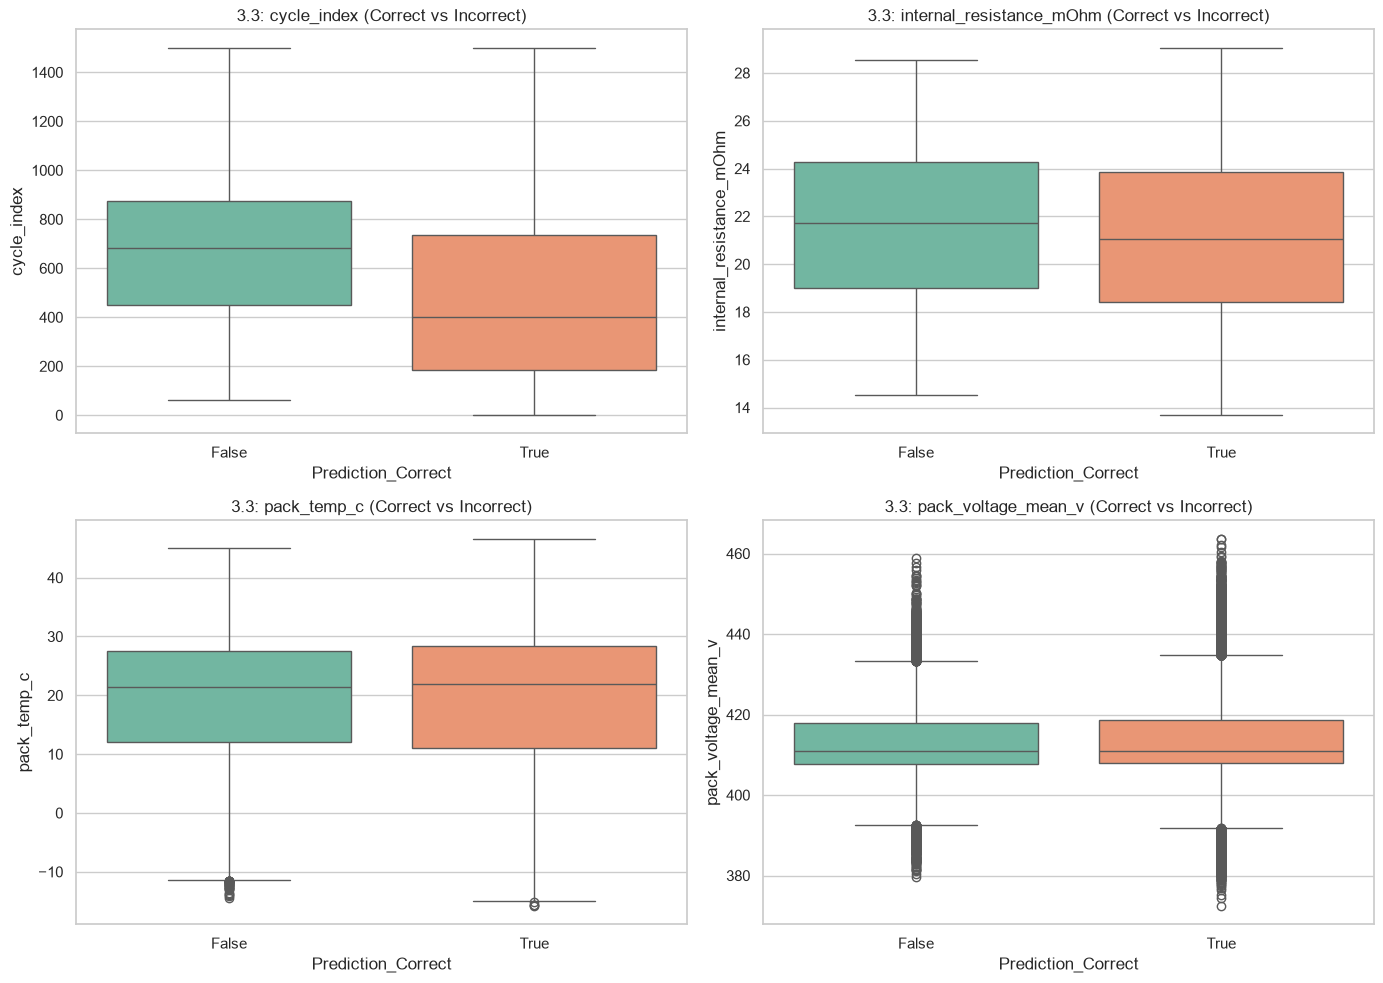

In [21]:
y_pred_proba = cross_val_predict(clf, X, y_class, cv=kf, method='predict_proba')[:, 1]
df_clean['Predicted_Proba'] = y_pred_proba
df_clean['Prediction_Correct'] = df_clean['Actual_Class'] == df_clean['Predicted_Class']

plt.figure(figsize=(10, 5))
sns.histplot(data=df_clean, x='Predicted_Proba', hue='Prediction_Correct', bins=50, kde=True, common_norm=False, palette='Set1')
plt.title('3.2: Predicted Probabilities for Correct vs Incorrect Predictions')
plt.xlabel('Predicted Probability of being Degraded')
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, feature in enumerate(features_to_plot):
    sns.boxplot(data=df_clean, x='Prediction_Correct', y=feature, ax=axes[i], palette='Set2')
    axes[i].set_title(f'3.3: {feature} (Correct vs Incorrect)')

plt.tight_layout()
plt.show()

### Section 3.2: Probability-Based Analysis

The plot compares the predicted probabilities for observations that were classified correctly (blue) versus those classified incorrectly (red).

* **Distribution of Correct Predictions:** As expected, the model is most accurate when its confidence is high. Most correct predictions are heavily concentrated at the extremes (probability near 0.0 for Healthy, or 1.0 for Degraded).
* **Identifying High-Confidence Errors:** The vast majority of errors (the red distribution) occur in the probability range of 0.3 to 0.7, a region where the model is uncertain. However, there is a noticeable presence of errors extending towards the extremes. There are cases where the model predicted a high probability of degradation (above 0.8) or a high probability of being healthy (below 0.2) and was still wrong. These high-confidence errors suggest the existence of physical edge cases in the data that cause the model to be completely certain of an incorrect prediction.

### Section 3.3: Error as a Function of Features (Classification)

By comparing the feature distributions between correct (True) and incorrect (False) predictions, we can identify specific regions prone to misclassification:

* **cycle_index:** This feature shows the most significant discrepancy. The median cycle index for incorrect predictions (around 700) is substantially higher than for correct predictions (around 400). The model systematically struggles and makes more errors on older batteries that have undergone many charge cycles.
* **internal_resistance_mOhm:** The distribution for incorrect predictions is slightly shifted upward compared to the correct ones. This suggests the model gets slightly more confused as internal resistance increases, though there is substantial overlap between the two groups.
* **pack_temp_c & pack_voltage_mean_v:** The medians and overall distributions for both correct and incorrect predictions are nearly identical across these two features. This indicates that, for our Random Forest classifier, temperature and voltage alone are not the primary drivers isolating the misclassifications. The main error region is heavily tied to the battery's age/cycle life.

,Threshold,Precision,Recall,F1-score,MCC
0,0.1,0.496119,0.973798,0.657342,0.512523
1,0.2,0.574237,0.925394,0.708702,0.579227
2,0.3,0.648248,0.855802,0.737704,0.615627
3,0.4,0.705538,0.790386,0.745556,0.629826
4,0.5,0.762314,0.703254,0.731594,0.624249
5,0.6,0.821042,0.600339,0.693556,0.602871
6,0.7,0.884610,0.477271,0.620023,0.560747
7,0.8,0.932710,0.369674,0.529488,0.507314
8,0.9,0.974376,0.250761,0.398870,0.425758


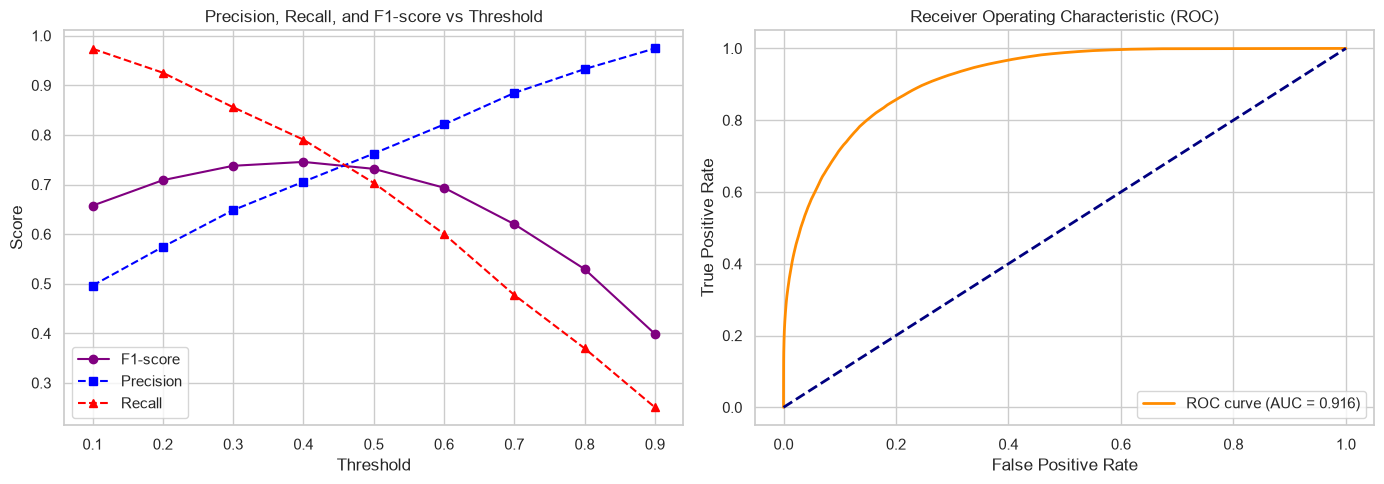

In [22]:
from sklearn.metrics import precision_score, recall_score, f1_score, matthews_corrcoef, roc_auc_score, roc_curve
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

thresholds = np.arange(0.1, 1.0, 0.1)
metrics_list = []

for thresh in thresholds:
    y_pred_thresh = (df_clean['Predicted_Proba'] >= thresh).astype(int)
    precision = precision_score(df_clean['Actual_Class'], y_pred_thresh, zero_division=0)
    recall = recall_score(df_clean['Actual_Class'], y_pred_thresh, zero_division=0)
    f1 = f1_score(df_clean['Actual_Class'], y_pred_thresh, zero_division=0)
    mcc = matthews_corrcoef(df_clean['Actual_Class'], y_pred_thresh)
    
    metrics_list.append({
        'Threshold': thresh, 
        'Precision': precision, 
        'Recall': recall, 
        'F1-score': f1, 
        'MCC': mcc
    })

metrics_df = pd.DataFrame(metrics_list)
display(metrics_df)

auc_roc = roc_auc_score(df_clean['Actual_Class'], df_clean['Predicted_Proba'])
fpr, tpr, _ = roc_curve(df_clean['Actual_Class'], df_clean['Predicted_Proba'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(metrics_df['Threshold'], metrics_df['F1-score'], marker='o', color='purple', label='F1-score')
axes[0].plot(metrics_df['Threshold'], metrics_df['Precision'], marker='s', linestyle='--', color='blue', label='Precision')
axes[0].plot(metrics_df['Threshold'], metrics_df['Recall'], marker='^', linestyle='--', color='red', label='Recall')
axes[0].set_xlabel('Threshold')
axes[0].set_ylabel('Score')
axes[0].set_title('Precision, Recall, and F1-score vs Threshold')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_roc:.3f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Receiver Operating Characteristic (ROC)')
axes[1].legend(loc="lower right")
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Section 3.4: Threshold Sensitivity Analysis

By evaluating the model across different probability thresholds (from 0.1 to 0.9), we analyzed the stability and performance trade-offs:

* **Precision-Recall Trade-off:** As the classification threshold increases, Precision steadily rises (fewer False Positives), while Recall decreases (more False Negatives are missed). 
* **Optimal Threshold:** The F1-score reaches its peak around a threshold of **0.4**, balancing both precision and recall more effectively than the default 0.5 threshold. Lowering the threshold to 0.4 helps capture more degraded batteries (improving Recall), which is crucial given that False Negatives are our most critical error type.
* **ROC Curve and AUC:** The ROC curve demonstrates strong model separation, yielding an **AUC of 0.916**. This confirms that the Random Forest classifier has a high overall capability to discriminate between healthy and degraded batteries across various operating points.

### Section 3.5: Discussion & Critical Reflection

Integrating insights from both the regression and classification stages, we can synthesize the overall performance and limitations of our modeling pipeline:

* **Model Strengths and Limitations:** The Random Forest models (both regressor and classifier) demonstrated high predictive power and robustness by successfully capturing non-linear interactions without making strict parametric assumptions. However, their limitation lies in interpretability and susceptibility to overfitting if hyperparameters are left uncontrolled.
* **Key Failure Modes:** The primary failure modes occur in boundary regions (e.g., SOH near the 80% threshold) and during accelerated degradation phases (mid-to-late cycle life), where linear approximations break down and complex variance spikes.
* **Assumptions vs. Performance:** The severe violation of linearity and homoskedasticity in the raw battery data directly caused the baseline models to underperform. Tree-based ensemble methods overcame this by locally partitioning the feature space.
* **Most Significant Insights:** Error analysis proved that model accuracy is heavily dependent on feature interactions (specifically `cycle_index`). Furthermore, relying on default classification thresholds (0.5) is suboptimal when dealing with critical safety tasks where False Negatives carry a much higher operational cost than False Positives.
* **Recommendations for Future Work:** To enhance robustness, future iterations should incorporate feature engineering (such as rolling averages of voltage drop rates), apply hyperparameter tuning, and use cost-sensitive learning to better penalize False Negatives.

---

### Section 4: Final Reflection

1. **Where does the model fail most?**
   The model fails most significantly in predicting batteries undergoing accelerated degradation (typically between 200–600 charge cycles) and around the critical 80% SOH classification boundary, where minor feature fluctuations flip the predicted class.

2. **Are failures due to data, model, or formulation?**
   The failures stem from a combination of all three: inherent physical noise and sensor variance in the data, the inability of simple linear formulations to capture complex degradation dynamics, and the initial reliance on a default 0.5 decision threshold that did not account for the asymmetry of error costs.

3. **What improvements would you propose?**
   We propose implementing advanced feature engineering (extraction of degradation rates), exploring gradient boosting algorithms (like XGBoost), and optimizing the classification decision threshold based on business/safety costs rather than defaulting to 0.5.

4. **What insights did you gain in your analysis?**
   The most valuable insight is that quantitative metrics (like $R^2$ or accuracy) only tell half the story. Systematic error analysis, residual evaluations, and threshold tuning are critical for uncovering *why* and *where* a model breaks down, transforming a black-box predictor into a reliable engineering tool.